In [11]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [12]:
df = pd.read_csv("smartcart_customers.csv")

In [14]:
df.isnull().sum()

ID                      0
Year_Birth              0
Education               0
Marital_Status          0
Income                 24
Kidhome                 0
Teenhome                0
Dt_Customer             0
Recency                 0
MntWines                0
MntFruits               0
MntMeatProducts         0
MntFishProducts         0
MntSweetProducts        0
MntGoldProds            0
NumDealsPurchases       0
NumWebPurchases         0
NumCatalogPurchases     0
NumStorePurchases       0
NumWebVisitsMonth       0
Complain                0
Response                0
dtype: int64

# Data Preprocessing



In [15]:
df["Income"] = df["Income"].fillna(df["Income"].median())

# Feature Engineering

In [16]:
#age

df["Age"] = 2026 - df["Year_Birth"]

In [17]:
#customer joining data

df["Dt_Customer"] = pd.to_datetime(df["Dt_Customer"],dayfirst = True)

reference_data = df["Dt_Customer"].max()

df["Customer_Tenure(Days)"] = (reference_data - df["Dt_Customer"]).dt.days



In [18]:
#Spending

df["Total_Spending"] = df["MntWines"] + df["MntFruits"] + df["MntMeatProducts"] + df["MntFishProducts"] +df["MntSweetProducts"] + df["MntGoldProds"] 

In [19]:
#Children

df["Total_Children"] = df["Kidhome"] + df["Teenhome"]

In [20]:
#Education

df["Education"] = df["Education"].str.strip()

df["Education"].value_counts()

df["Education"] = df["Education"].replace({
    "Basic" : "Undergraduate" ,
    "2n Cycle": "Undergraduate" ,
    "Graduation" : "Graduate",
    "Master" : "Postgraduate" ,
    "PhD" : "Postgraduate"
})

In [21]:
# Marital status

df['Living_With'] = df['Marital_Status'].replace({
    'Married': 'Partner', 'Together': 'Partner',
    'Single': 'Alone', "Divorced": "Alone",
    'Widow': 'Alone', 'Absurd': 'Alone', 'YOLO': 'Alone'
})

In [22]:
df["Living_With"].value_counts()

Living_With
Partner    1444
Alone       796
Name: count, dtype: int64

# Drop columns



In [23]:
cols = ["ID" ,"Year_Birth" ,"Marital_Status" , "Kidhome", "Teenhome" , "Dt_Customer" ]
spending_cols = ["MntWines","MntFruits" , "MntMeatProducts" , "MntFishProducts" , "MntSweetProducts" , "MntGoldProds" ]

cols_to_drop = cols + spending_cols

df_cleaned = df.drop(columns = cols_to_drop)

# Outliers

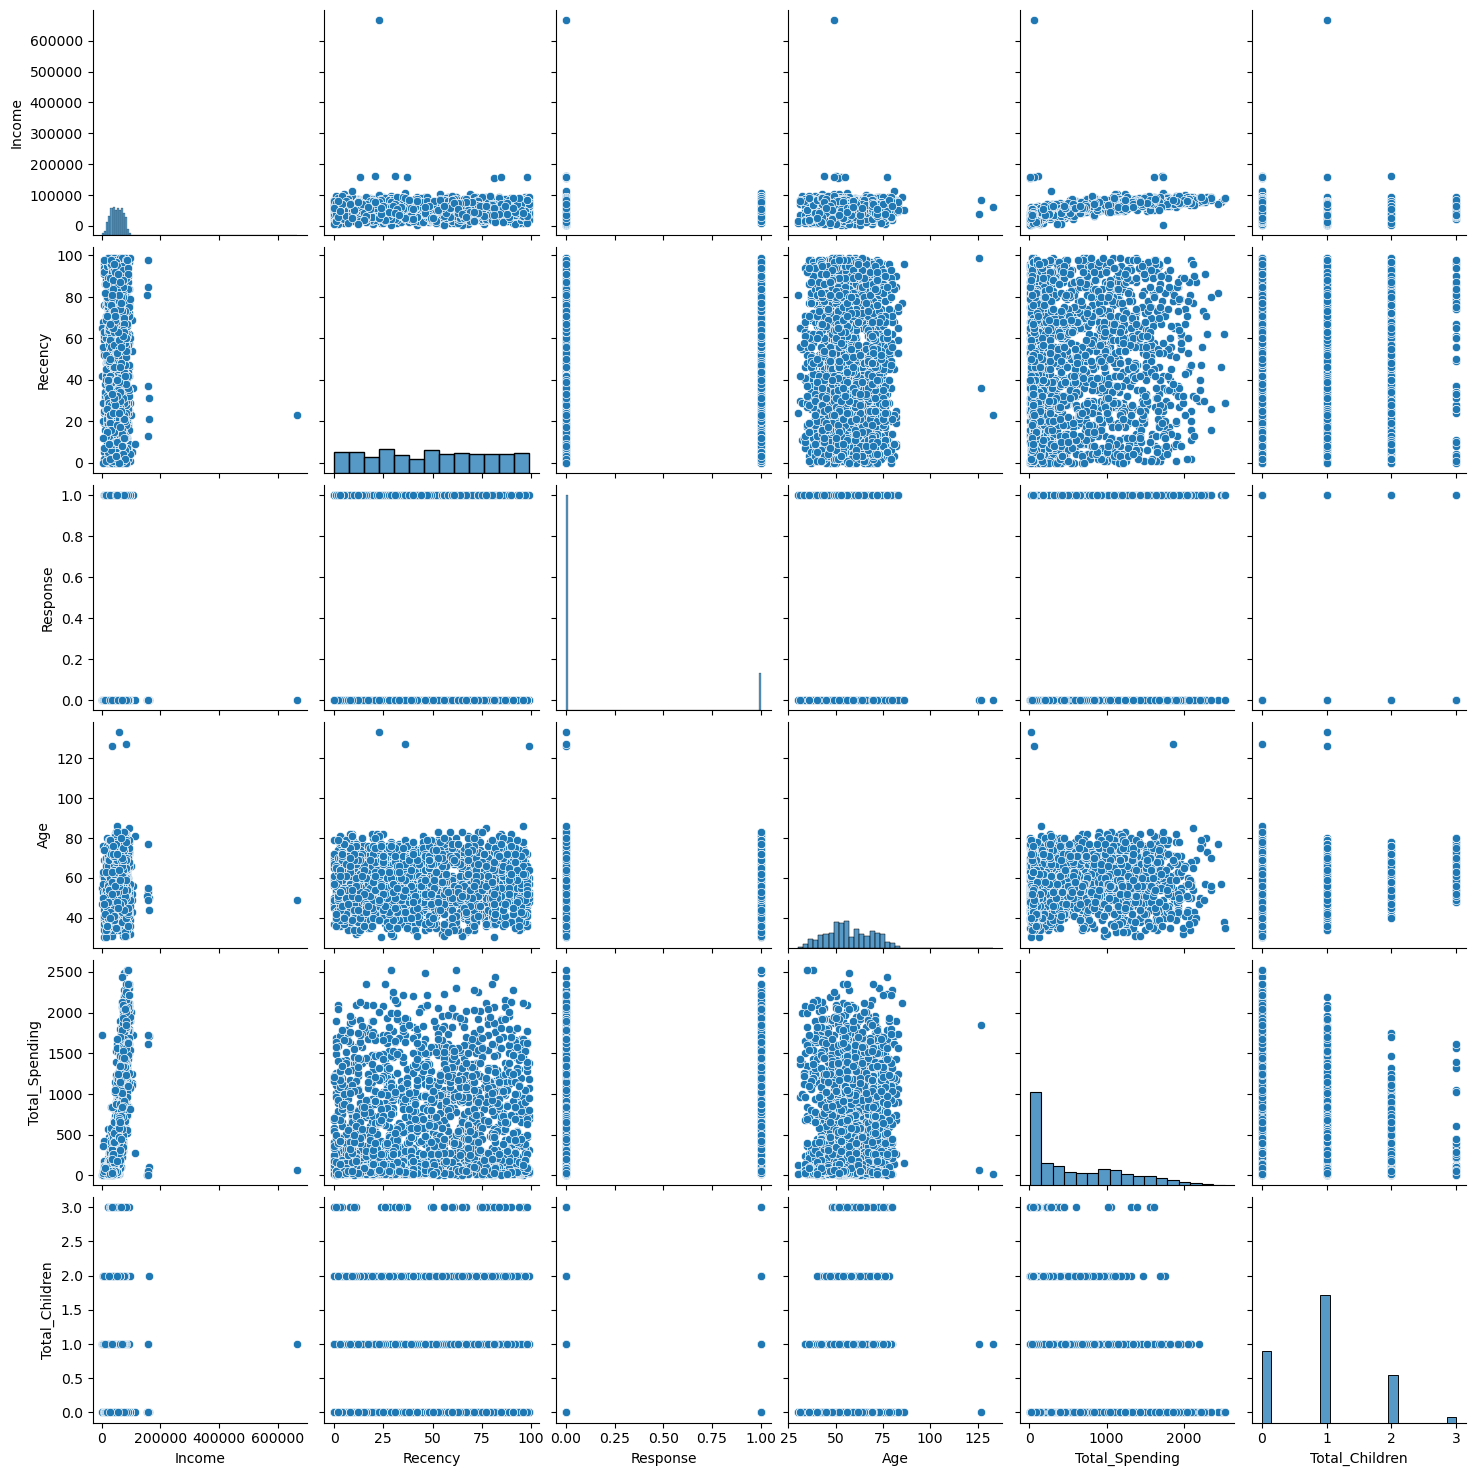

In [24]:
cols = ["Income","Recency","Response","Age","Total_Spending","Total_Children"]
sns.pairplot(df_cleaned[cols])

In [25]:
# Remove outliers

print("data size with outliers", len(df_cleaned))

df_cleaned = df_cleaned[(df_cleaned["Age"] < 90)]
df_cleaned = df_cleaned[(df_cleaned["Income"] < 600_000)]

print("data size without outliers", len(df_cleaned))

data size with outliers 2240
data size without outliers 2236


# Heatmap

In [26]:
corr = df_cleaned.corr(numeric_only=True)

<Axes: >

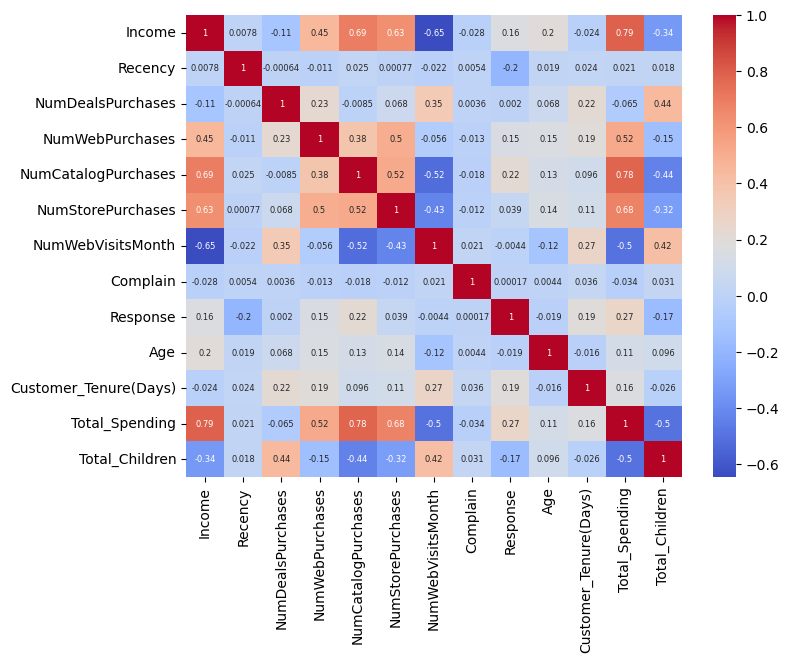

In [29]:
plt.figure(figsize=(8,6))

sns.heatmap(
    corr,
    annot = True,
    annot_kws = {"size" : 6},
    cmap = "coolwarm"
)


In [30]:
from sklearn.preprocessing import OneHotEncoder



In [34]:
ohe = OneHotEncoder()

cat_cols = ["Education", "Living_With"]

enc_cols = ohe.fit_transform(df_cleaned[cat_cols])

In [36]:
enc_df = pd.DataFrame(enc_cols.toarray(),columns = ohe.get_feature_names_out(cat_cols), index = df_cleaned.index)

In [39]:
df_encoded = pd.concat([df_cleaned.drop(columns = cat_cols),enc_df], axis = 1)

In [40]:
df_encoded.head()

,Income,Recency,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response,Age,Customer_Tenure(Days),Total_Spending,Total_Children,Education_Graduate,Education_Postgraduate,Education_Undergraduate,Living_With_Alone,Living_With_Partner
0,58138.0,58,3,8,10,4,7,0,1,69,663,1617,0,1.0,0.0,0.0,1.0,0.0
1,46344.0,38,2,1,1,2,5,0,0,72,113,27,2,1.0,0.0,0.0,1.0,0.0
2,71613.0,26,1,8,2,10,4,0,0,61,312,776,0,1.0,0.0,0.0,0.0,1.0
3,26646.0,26,2,2,0,4,6,0,0,42,139,53,1,1.0,0.0,0.0,0.0,1.0
4,58293.0,94,5,5,3,6,5,0,0,45,161,422,1,0.0,1.0,0.0,0.0,1.0


# Scaling

In [51]:
from sklearn.preprocessing import StandardScaler 

In [52]:
X = df_encoded

In [54]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)


# Visualize

In [44]:
from sklearn.decomposition import PCA

In [57]:
pca = PCA(n_components = 3)
X_pca = pca.fit_transform(X_scaled)

Text(0.5, 0.92, '3D_Projection')

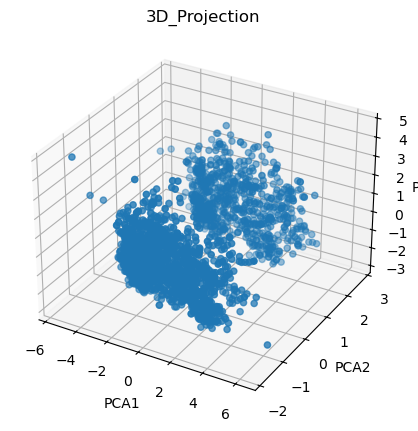

In [63]:
fig = plt.figure(figsize = (7,5))

ax = fig.add_subplot(111, projection = "3d")

ax.scatter(X_pca[:,0] , X_pca[:,1] , X_pca[:,2] )
ax.set_xlabel("PCA1")
ax.set_ylabel("PCA2")
ax.set_zlabel("PCA3")
ax.set_title("3D_Projection")


In [64]:
pca.explained_variance_ratio_

array([0.23163158, 0.11385454, 0.10405815])

# Analyse K Value

# 1. Elbow Method

In [70]:
from sklearn.cluster import KMeans
from kneed import KneeLocator

wcss = []
for k in range (1 , 11):
    kmeans = KMeans(n_clusters = k, random_state = 42)
    kmeans.fit_predict(X_pca)
    wcss.append(kmeans.inertia_)

In [71]:
knee = KneeLocator(range(1,11), wcss , curve = "convex" , direction = "decreasing")
optimal_k = knee.elbow

In [72]:
wcss

[18093.25779332454,
 10760.843401758235,
 8830.288717243038,
 6650.96941765886,
 5006.161168001188,
 4396.308699108107,
 3857.6330644275854,
 3207.0576242216966,
 3025.2232554326156,
 2651.442989106173]

In [73]:
print("best k  = ", optimal_k)

best k  =  4


Text(0, 0.5, 'WCSS')

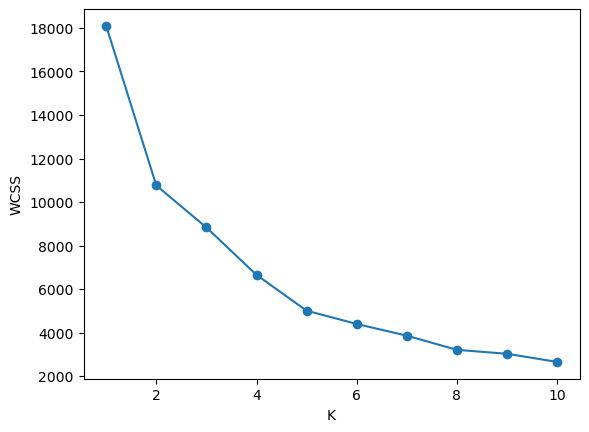

In [74]:
plt.plot(range(1,11) ,wcss , marker = "o" )
plt.xlabel("K")
plt.ylabel("WCSS")


# Shilloete score

Text(0, 0.5, 'Silhouette score')

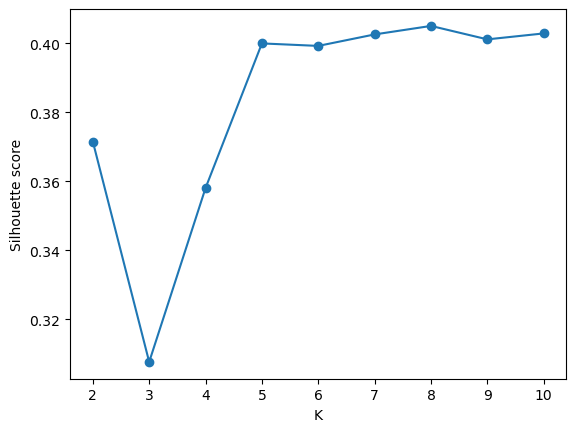

In [78]:
from sklearn.metrics import silhouette_score

scores = []

for k in range(2,11):
    kmeans = KMeans(n_clusters = k ,random_state =42)
    labels = kmeans.fit_predict(X_pca)
    score = silhouette_score(X_pca , labels)
    scores.append(score)

#plot

plt.plot(range(2,11) , scores , marker = "o" )
plt.xlabel("K")
plt.ylabel("Silhouette score")


Text(0, 0.5, 'Shilouette score')

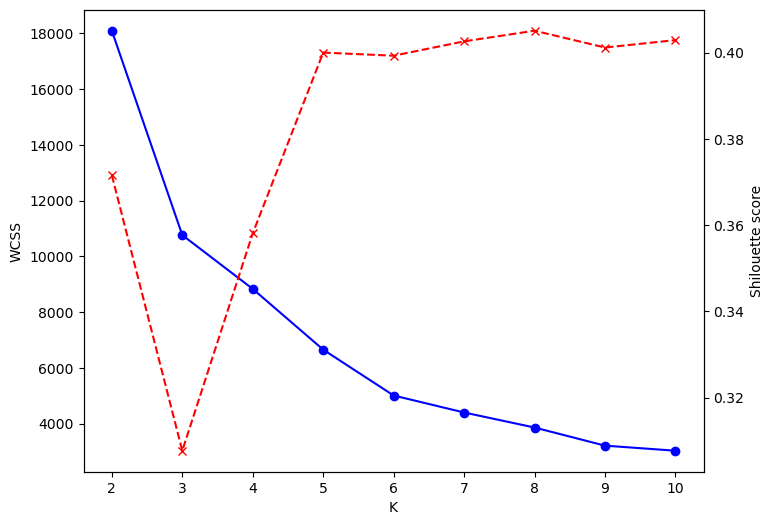

In [92]:
# combine plot

k_range = range(2,11)
fig , ax1 = plt.subplots(figsize = (8,6))

ax1.plot(k_range , wcss[:len(k_range)] , marker = "o" , color = "blue")
ax1.set_xlabel("K")
ax1.set_ylabel("WCSS")

ax2 = ax1.twinx()
ax2.plot(k_range , scores[:len(k_range)] , marker = "x" , color = "red" , linestyle = "--")
ax2.set_ylabel("Shilouette score")

# Clustering

In [93]:
#Kmeans

kmeans  = KMeans(n_clusters = 4 , random_state = 42)
labels_kmeans  = kmeans.fit_predict(X_pca)

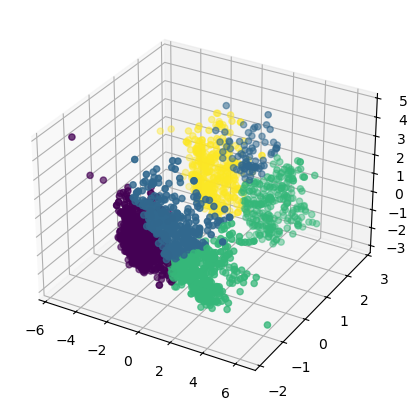

In [94]:
fig = plt.figure(figsize = (7,5))

ax = fig.add_subplot(111, projection = "3d")

ax.scatter(X_pca[:,0] , X_pca[:,1] , X_pca[:,2] , c = labels_kmeans )

In [95]:
# Agglomerative Clustering

from sklearn.cluster import AgglomerativeClustering


In [96]:
agg_clf = AgglomerativeClustering(n_clusters = 4 , linkage= "ward")
labels_agg = agg_clf.fit_predict(X_pca)

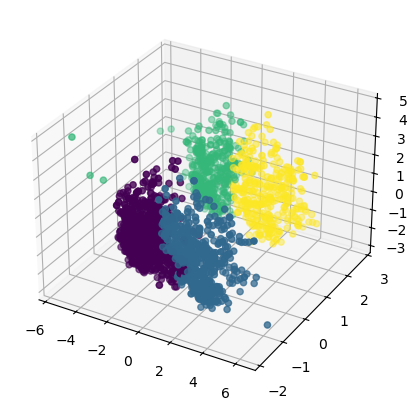

In [97]:
fig = plt.figure(figsize = (7,5))

ax = fig.add_subplot(111, projection = "3d")

ax.scatter(X_pca[:,0] , X_pca[:,1] , X_pca[:,2] , c = labels_agg )

# Characterization of clusters

In [106]:
X["clusters"] = labels_agg

<Axes: xlabel='clusters', ylabel='count'>

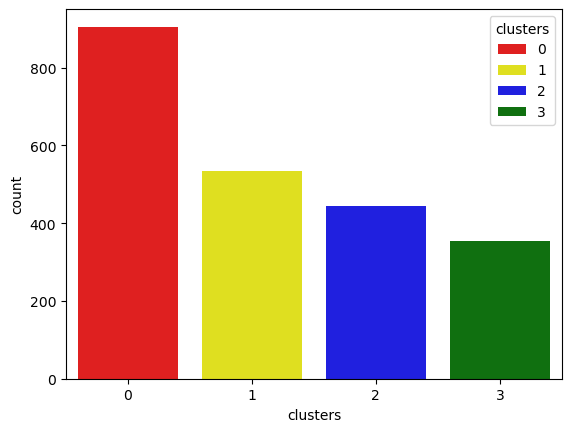

In [107]:
pal = ["red","yellow","blue","green"]

sns.countplot(x=X["clusters"] , palette = pal , hue = X["clusters"])


<Axes: xlabel='Total_Spending', ylabel='Income'>

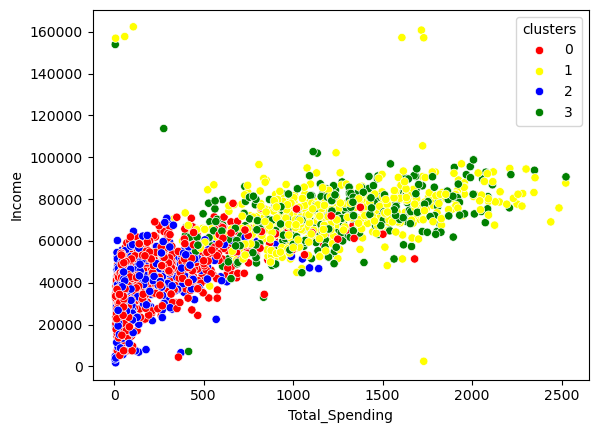

In [103]:
# income and spending patterns
sns.scatterplot(x = df_cleaned["Total_Spending"], y =df_cleaned["Income"] , hue = df_cleaned["clusters"], palette = pal)

In [109]:
cluster_summary = X.groupby("clusters").mean()
print(cluster_summary)

                Income    Recency  NumDealsPurchases  NumWebPurchases  \
clusters                                                                
0         39680.580110  48.914917           2.594475         3.153591   
1         72808.445693  49.202247           1.958801         5.687266   
2         36960.143018  48.319820           2.594595         2.713964   
3         70722.681303  50.504249           1.855524         5.790368   

          NumCatalogPurchases  NumStorePurchases  NumWebVisitsMonth  Complain  \
clusters                                                                        
0                    0.969061           4.143646           6.307182  0.011050   
1                    5.498127           8.659176           3.580524  0.005618   
2                    0.837838           3.623874           6.659910  0.011261   
3                    5.014164           8.430595           3.728045  0.005666   

          Response        Age  Customer_Tenure(Days)  Total_Spending  \
cl